# Analisis Persebaran Topik Berita Geopolitik: LDA vs BERTopic + Visualisasi UMAP

Notebook ini membandingkan dua pendekatan *topic modeling* pada korpus artikel berita geopolitik CNBC (`news_processed_unmerged.csv`):
1. **LDA (Latent Dirichlet Allocation)** — model generatif berbasis *Bag-of-Words* dengan *tuning* jumlah topik berdasarkan *Topic Coherence* ($c_v$).
2. **BERTopic** — model topik berbasis *transformer embeddings* (`all-MiniLM-L6-v2`), reduksi dimensi **UMAP**, klastering **HDBSCAN**, dan representasi **c-TF-IDF + MMR**.

Fokus utama notebook ini:
- Melihat **persebaran topik** (proporsi artikel, kata kunci dominan, dan dinamika topik dari waktu ke waktu).
- Menampilkan **visualisasi UMAP hasil clustering** (baik statis resolusi tinggi maupun interaktif dengan *hover* judul berita).
- Membandingkan **LDA vs BERTopic** secara kuantitatif (*Coherence $c_v$*, *Topic Diversity*, *Silhouette Score* di ruang UMAP, *Entropy* distribusi, serta keselarasan klaster ARI/NMI & *cross-tabulation*).


## 1. Setup & Konfigurasi Lingkungan


In [1]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["USE_TF"] = "0"

import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)

from gensim.corpora import Dictionary
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel

from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from bertopic.representation import MaximalMarginalRelevance

warnings.filterwarnings("ignore")
pio.renderers.default = "notebook"

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})
sns.set_style("whitegrid")
print("Semua library berhasil dimuat.")


C:\Users\grace\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Semua library berhasil dimuat.


## 2. Pemuatan Dataset & Eksplorasi Awal


In [ ]:
DATA_CANDIDATES = [
    Path("data/processed/news_processed_unmerged.csv"),
    Path("../data/processed/news_processed_unmerged.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Tidak menemukan data/processed/news_processed_unmerged.csv. "
        "Pastikan notebook dijalankan dari root proyek atau folder notebook/."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset dimuat dari : {DATA_PATH}")
print(f"Jumlah baris awal   : {len(df_raw):,}")
print(f"Kolom tersedia      : {list(df_raw.columns)}")

# Bersihkan dan deduplikasi artikel
df = (
    df_raw.dropna(subset=["title", "text_lemmatized", "normalized_text"])
    .drop_duplicates(subset=["text_lemmatized"])
    .reset_index(drop=True)
)

df["date"] = pd.to_datetime(df["tanggal"], errors="coerce")
df = df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)
df["year_quarter"] = df["date"].dt.to_period("Q").astype(str)
df["word_count"] = df["text_lemmatized"].astype(str).str.split().str.len()

print(f"Jumlah artikel unik : {len(df):,}")
print(f"Rentang tanggal     : {df['date'].min().date()} s/d {df['date'].max().date()}")
print(f"Rata-rata kata/art. : {df['word_count'].mean():.1f} (median: {df['word_count'].median():.0f})")

df[["date", "title", "word_count"]].head(5)


## 3. Persiapan Teks untuk LDA & BERTopic

Agar perbandingan adil namun tetap sesuai kekuatan masing-masing model:
- **Teks Semantik (`docs_semantic`)**: gabungan `title` + potongan awal `normalized_text` (bahasa alami dengan konteks kalimat utuh) untuk menghasilkan *embedding* `all-MiniLM-L6-v2` yang akurat.
- **Teks Lemmatized (`docs_bow` & `tokens_clean`)**: memakai `text_lemmatized` yang sudah dibersihkan ditambah daftar *stopwords* generik berita/jurnalistik (`said`, `say`, `cnbc`, `year`, `percent`, `month`, `week`, dll.) agar kata kunci topik LDA maupun c-TF-IDF BERTopic lebih tajam dan informatif.


In [3]:
NEWS_EXTRA_STOPWORDS = {
    "say", "said", "tell", "told", "accord", "according", "cnbc", "report", "reported",
    "add", "added", "note", "noted", "include", "including", "also", "would", "could",
    "may", "might", "must", "need", "want", "like", "make", "made", "get", "got",
    "go", "going", "come", "came", "see", "seen", "know", "think", "look", "take",
    "give", "use", "used", "using", "way", "well", "even", "still", "much", "many",
    "year", "years", "month", "months", "week", "weeks", "day", "days", "time",
    "today", "monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday",
    "january", "february", "march", "april", "june", "july", "august", "september",
    "october", "november", "december", "last", "next", "first", "second", "third",
    "one", "two", "three", "four", "five", "new", "high", "low", "big", "large",
    "percent", "percentage", "people", "country", "countries", "world", "global",
    "state", "states", "government", "official", "officials", "company", "companies",
    "market", "markets", "continue", "continued", "remain", "show", "follow",
}

COMBINED_STOPWORDS = set(ENGLISH_STOP_WORDS) | NEWS_EXTRA_STOPWORDS

def clean_bow_tokens(text: str) -> list[str]:
    tokens = re.findall(r"[a-z]{3,}", str(text).lower())
    return [t for t in tokens if t not in COMBINED_STOPWORDS]

def build_semantic_doc(title: str, norm_text: str, max_chars: int = 600) -> str:
    t = re.sub(r"\s+", " ", str(title)).strip()
    b = re.sub(r"\s+", " ", str(norm_text)).strip()
    return f"{t}. {b[:max_chars]}"

df["docs_semantic"] = [
    build_semantic_doc(t, b) for t, b in zip(df["title"], df["normalized_text"])
]
tokens_clean = [clean_bow_tokens(txt) for txt in df["text_lemmatized"]]
df["docs_bow"] = [" ".join(toks) for toks in tokens_clean]

docs_semantic = df["docs_semantic"].tolist()
docs_bow = df["docs_bow"].tolist()
timestamps = df["date"].tolist()

# Kamus & korpus bersama untuk evaluasi Coherence (c_v) yang adil antara LDA dan BERTopic
shared_dictionary = Dictionary(tokens_clean)
shared_dictionary.filter_extremes(no_below=5, no_above=0.65, keep_n=2000)
shared_corpus = [shared_dictionary.doc2bow(toks) for toks in tokens_clean]

print(f"Ukuran vocabulary kamus bersama : {len(shared_dictionary):,} kata unik")
print(f"Rata-rata token bersih/artikel   : {np.mean([len(t) for t in tokens_clean]):.1f} token")


Ukuran vocabulary kamus bersama : 2,000 kata unik
Rata-rata token bersih/artikel   : 390.7 token


## 4. Topic Modeling dengan LDA (*Latent Dirichlet Allocation*)

Kita melakukan *tuning* jumlah topik $K \in \{6, 8, 10, 12\}$ menggunakan skor **Coherence ($c_v$)** dan **Topic Diversity** pada kamus bersama, lalu melatih model LDA terbaik.


K= 6 | Coherence c_v = 0.6417 | Diversity = 0.8167


K= 8 | Coherence c_v = 0.6601 | Diversity = 0.8250


K=10 | Coherence c_v = 0.6526 | Diversity = 0.7700


K=12 | Coherence c_v = 0.6556 | Diversity = 0.7250

>>> Jumlah topik LDA terbaik berdasarkan c_v: K = 8


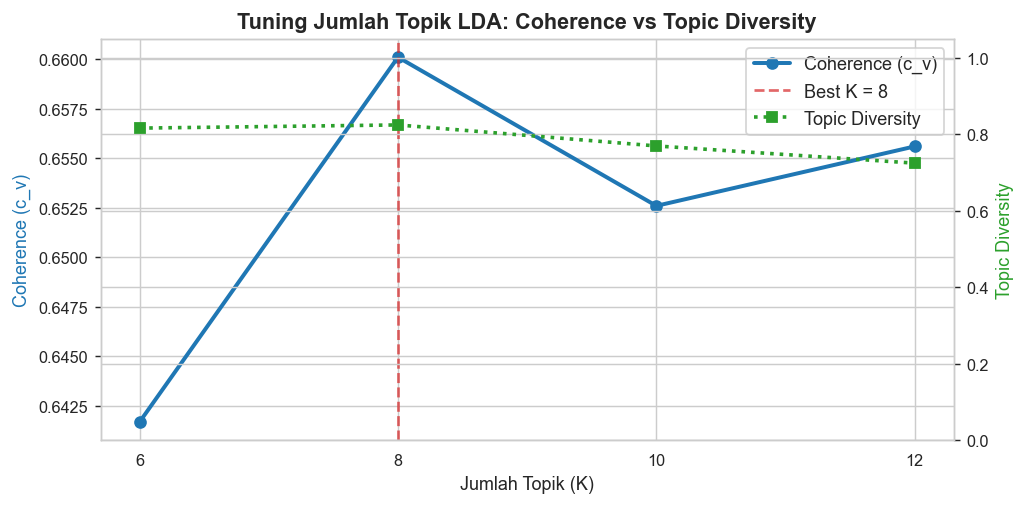

In [4]:
k_candidates = [6, 8, 10, 12]
lda_tuning_rows = []
lda_models = {}

for k in k_candidates:
    model_k = LdaModel(
        corpus=shared_corpus,
        id2word=shared_dictionary,
        num_topics=k,
        random_state=SEED,
        passes=5,
        iterations=60,
        chunksize=2000,
        alpha="auto",
        eta="auto",
        per_word_topics=False,
    )
    topic_words_k = [
        [w for w, _ in model_k.show_topic(tid, topn=10)] for tid in range(k)
    ]
    coh_k = CoherenceModel(
        topics=topic_words_k,
        texts=tokens_clean,
        dictionary=shared_dictionary,
        coherence="c_v",
        processes=1,
    ).get_coherence()
    div_k = len({w for ws in topic_words_k for w in ws}) / (k * 10)
    lda_models[k] = model_k
    lda_tuning_rows.append({
        "K": k,
        "Coherence (c_v)": round(coh_k, 4),
        "Topic Diversity": round(div_k, 4),
    })
    print(f"K={k:2d} | Coherence c_v = {coh_k:.4f} | Diversity = {div_k:.4f}")

lda_tuning_df = pd.DataFrame(lda_tuning_rows)
best_k = int(lda_tuning_df.loc[lda_tuning_df["Coherence (c_v)"].idxmax(), "K"])
print(f"\n>>> Jumlah topik LDA terbaik berdasarkan c_v: K = {best_k}")

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(lda_tuning_df["K"], lda_tuning_df["Coherence (c_v)"], marker="o", lw=2.2, color="#1f77b4", label="Coherence (c_v)")
ax1.axvline(best_k, color="#d62728", linestyle="--", alpha=0.7, label=f"Best K = {best_k}")
ax1.set_xlabel("Jumlah Topik (K)")
ax1.set_ylabel("Coherence (c_v)", color="#1f77b4")
ax1.set_xticks(k_candidates)

ax2 = ax1.twinx()
ax2.plot(lda_tuning_df["K"], lda_tuning_df["Topic Diversity"], marker="s", lw=2, linestyle=":", color="#2ca02c", label="Topic Diversity")
ax2.set_ylabel("Topic Diversity", color="#2ca02c")
ax2.set_ylim(0, 1.05)

plt.title("Tuning Jumlah Topik LDA: Coherence vs Topic Diversity")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")
plt.tight_layout()
plt.show()


In [5]:
# Model LDA final dengan K terbaik (lebih banyak passes agar konvergen stabil)
lda_model = LdaModel(
    corpus=shared_corpus,
    id2word=shared_dictionary,
    num_topics=best_k,
    random_state=SEED,
    passes=8,
    iterations=100,
    chunksize=2000,
    alpha="auto",
    eta="auto",
    minimum_probability=0.0,
)

# Matriks probabilitas topik per dokumen (N x K)
lda_topic_dist = np.zeros((len(shared_corpus), best_k), dtype=np.float32)
for i, bow in enumerate(shared_corpus):
    for tid, prob in lda_model.get_document_topics(bow, minimum_probability=0.0):
        lda_topic_dist[i, tid] = prob

df["lda_topic"] = lda_topic_dist.argmax(axis=1)
df["lda_prob"] = lda_topic_dist.max(axis=1)

# Bangun ringkasan topik LDA
lda_topic_labels = {}
lda_summary_rows = []
for tid in range(best_k):
    top_terms = lda_model.show_topic(tid, topn=10)
    words = [w for w, _ in top_terms]
    label = f"LDA-{tid}: {', '.join(words[:3])}"
    lda_topic_labels[tid] = label
    cnt = int((df["lda_topic"] == tid).sum())
    mean_w = float(lda_topic_dist[:, tid].mean())
    lda_summary_rows.append({
        "Topic_ID": tid,
        "Label": label,
        "Count": cnt,
        "Share (%)": round(cnt / len(df) * 100, 2),
        "Mean Prob": round(mean_w, 4),
        "Top_10_Words": ", ".join(words),
    })

df["lda_label"] = df["lda_topic"].map(lda_topic_labels)
lda_summary_df = pd.DataFrame(lda_summary_rows).sort_values("Count", ascending=False).reset_index(drop=True)
lda_summary_df


,Topic_ID,Label,Count,Share (%),Mean Prob,Top_10_Words
0,1,"LDA-1: rate, inflation, dollar",778,17.95,0.1656,"rate, inflation, dollar, bank, price, economy,..."
1,4,"LDA-4: china, chinese, technology",627,14.46,0.1400,"china, chinese, technology, tech, investment, ..."
2,2,"LDA-2: ukraine, russia, russian",620,14.30,0.1445,"ukraine, russia, russian, war, military, defen..."
3,6,"LDA-6: dollar, stock, billion",530,12.23,0.1256,"dollar, stock, billion, price, analyst, invest..."
4,7,"LDA-7: trump, president, tariff",523,12.06,0.1356,"trump, president, tariff, house, administratio..."
5,3,"LDA-3: oil, price, energy",513,11.83,0.1054,"oil, price, energy, supply, barrel, dollar, cr..."
6,5,"LDA-5: iran, strait, trump",458,10.57,0.1050,"iran, strait, trump, iranian, israel, war, att..."
7,0,"LDA-0: china, chinese, beijing",286,6.60,0.0783,"china, chinese, beijing, trade, india, taiwan,..."


### 4.1 Visualisasi Persebaran Topik LDA


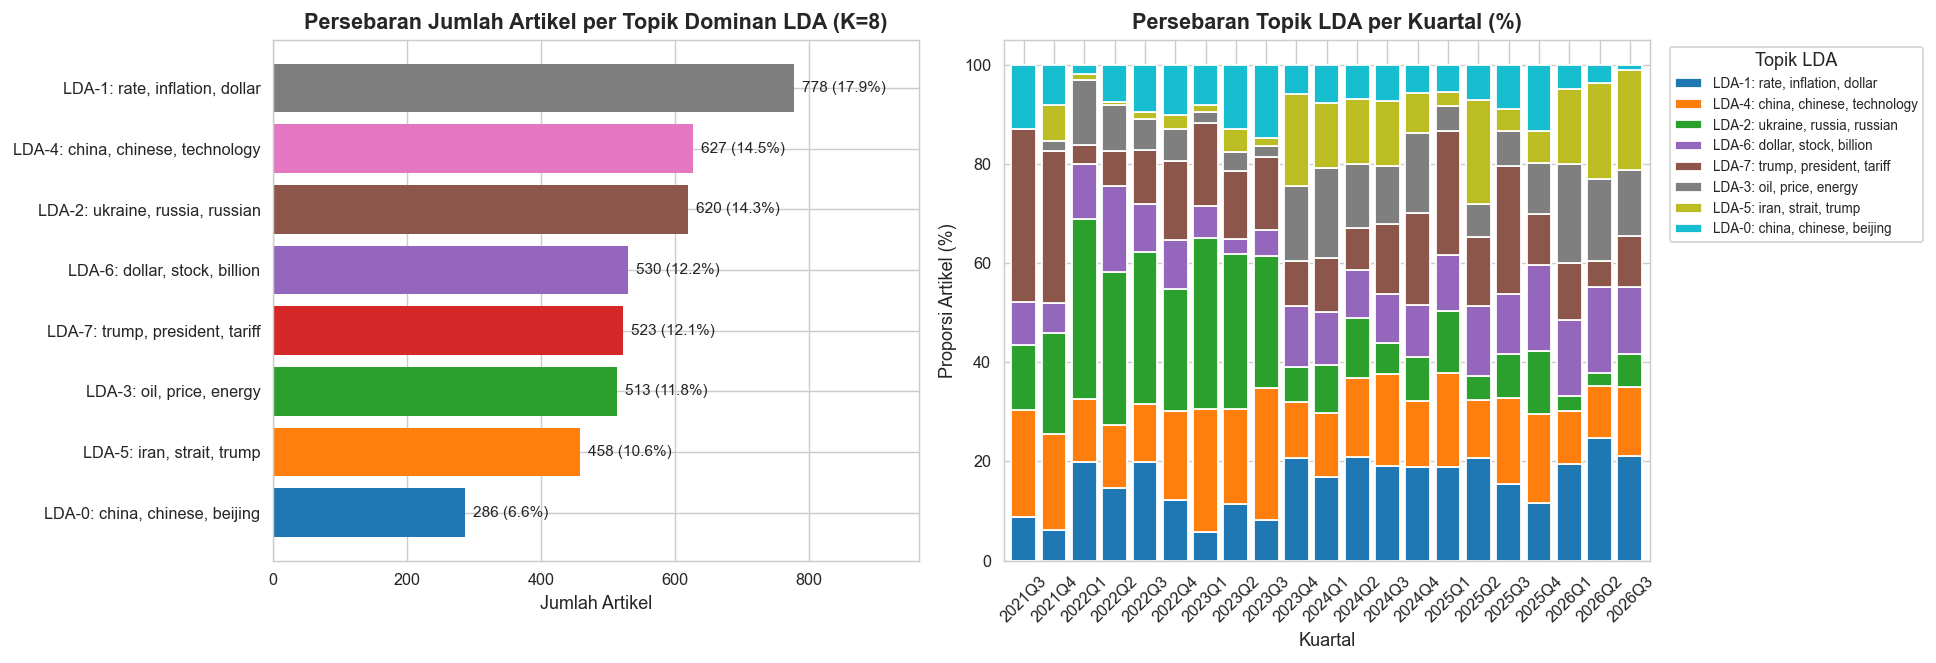

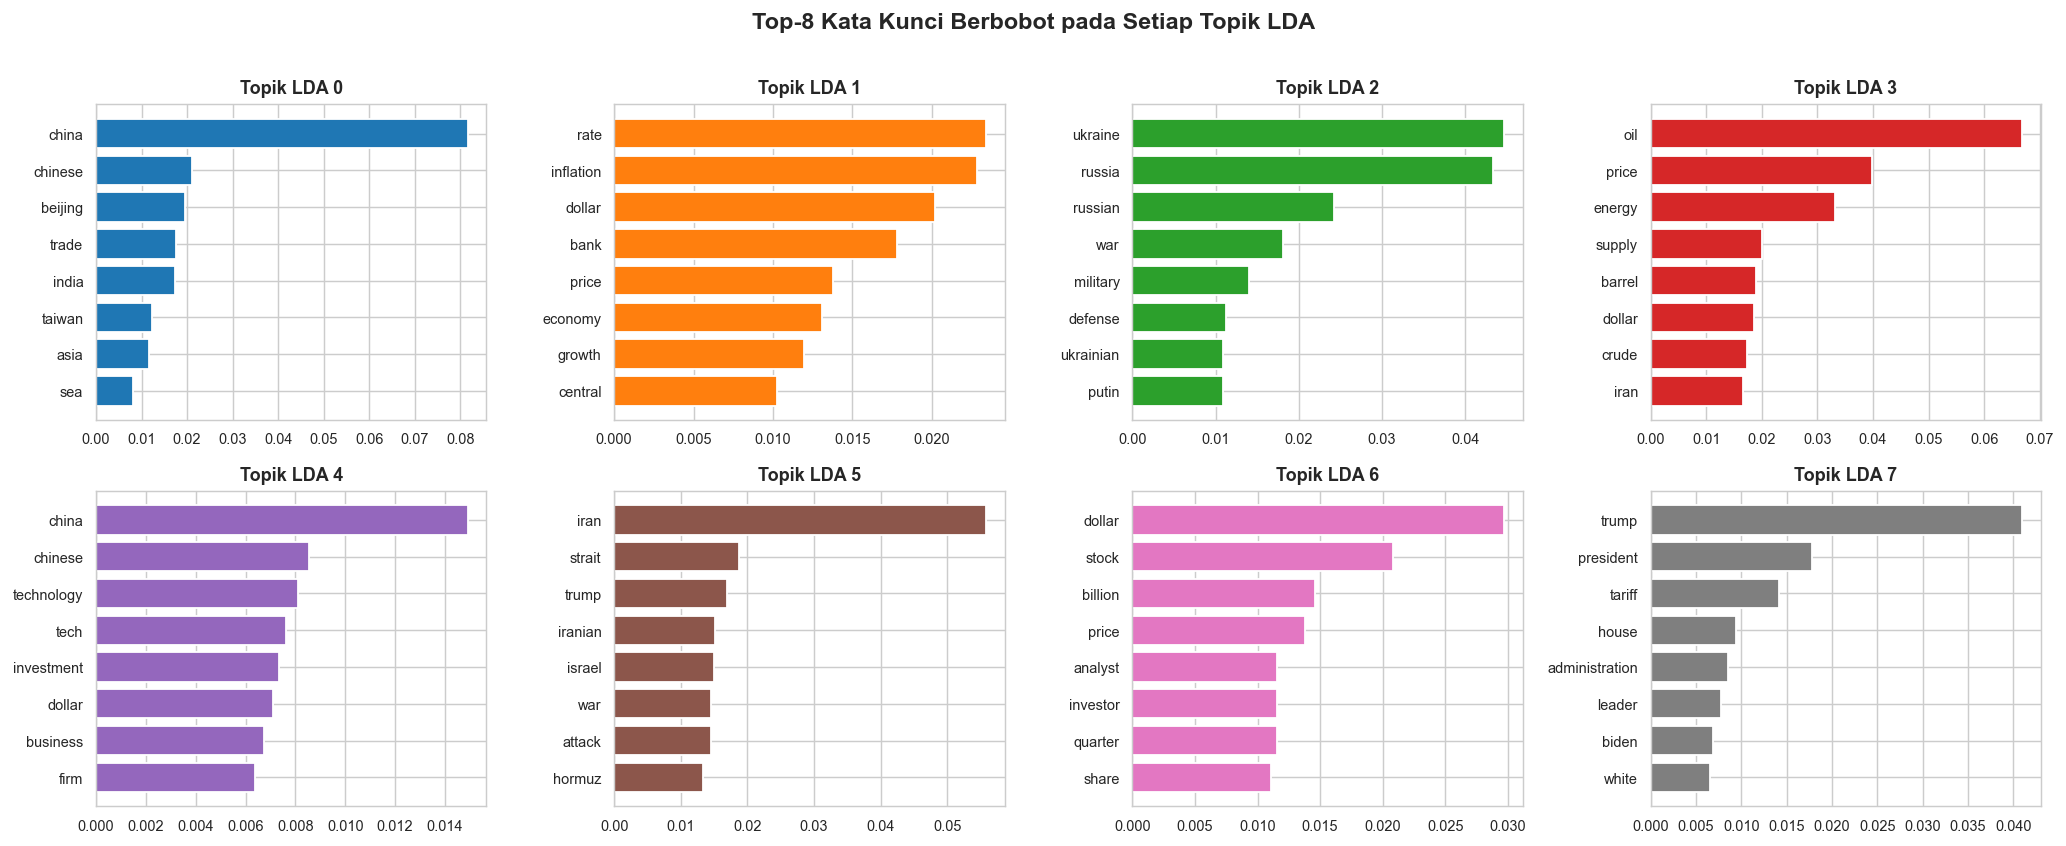

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Panel 1: Jumlah & proporsi artikel per topik dominan LDA
plot_lda = lda_summary_df.sort_values("Count", ascending=True)
colors_lda = sns.color_palette("tab10", n_colors=len(plot_lda))
bars = axes[0].barh(plot_lda["Label"], plot_lda["Count"], color=colors_lda, edgecolor="none")
for bar, (_, row) in zip(bars, plot_lda.iterrows()):
    axes[0].text(
        bar.get_width() + 12,
        bar.get_y() + bar.get_height() / 2,
        f"{row['Count']} ({row['Share (%)']:.1f}%)",
        va="center",
        fontsize=8.5,
    )
axes[0].set_xlim(0, plot_lda["Count"].max() * 1.24)
axes[0].set_title(f"Persebaran Jumlah Artikel per Topik Dominan LDA (K={best_k})")
axes[0].set_xlabel("Jumlah Artikel")

# Panel 2: Dinamika proporsi topik LDA per kuartal
lda_quarter = pd.crosstab(df["year_quarter"], df["lda_label"], normalize="index") * 100
lda_quarter = lda_quarter[lda_summary_df["Label"].tolist()]
lda_quarter.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10", width=0.82)
axes[1].set_title("Persebaran Topik LDA per Kuartal (%)")
axes[1].set_ylabel("Proporsi Artikel (%)")
axes[1].set_xlabel("Kuartal")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7.5, title="Topik LDA")

plt.tight_layout()
plt.show()

# Multi-panel kata kunci berbobot untuk setiap topik LDA
ncols = 4
nrows = int(np.ceil(best_k / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
axes = np.array(axes).flatten()

for tid in range(best_k):
    ax = axes[tid]
    terms = lda_model.show_topic(tid, topn=8)[::-1]
    words = [w for w, _ in terms]
    weights = [p for _, p in terms]
    ax.barh(words, weights, color=sns.color_palette("tab10", best_k)[tid % 10])
    ax.set_title(f"Topik LDA {tid}", fontsize=10)
    ax.tick_params(labelsize=8)

for j in range(best_k, len(axes)):
    axes[j].axis("off")

plt.suptitle("Top-8 Kata Kunci Berbobot pada Setiap Topik LDA", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


## 5. Topic Modeling dengan BERTopic

Berbeda dengan LDA yang hanya mengandalkan frekuensi kata (*bag-of-words*), **BERTopic** memanfaatkan *semantic embeddings* (`all-MiniLM-L6-v2`) yang direduksi dengan **UMAP (5D)**, dikelompokkan oleh **HDBSCAN**, dan diberi label kata kunci melalui **c-TF-IDF + MMR**.

Setelah klaster awal terbentuk, kita juga melihat jumlah *outlier* (`Topic == -1`) lalu menerapkan reduksi *outlier* berbasis kesamaan *embedding*.


In [ ]:
import torch
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
# Bekukan seluruh bobot encoder (Freeze Weights) agar ekstraksi cepat dan bebas fine-tuning
for param in embedding_model.parameters():
    param.requires_grad = False
embedding_model.eval()

print(f"Menghitung embedding {len(docs_semantic):,} artikel dengan all-MiniLM-L6-v2 (Freeze Weights, No Cache)...")
with torch.no_grad():
    embeddings = embedding_model.encode(docs_semantic, show_progress_bar=True, batch_size=64, normalize_embeddings=True)
print(f"Embedding selesai dihitung di memori: {embeddings.shape}")


In [ ]:
# Hyperparameter Tuning BERTopic (min_cluster_size & n_neighbors) berdasarkan Coherence (c_v)
vectorizer_model = CountVectorizer(
    stop_words=sorted(COMBINED_STOPWORDS),
    min_df=5,
    ngram_range=(1, 2),
)
ctfidf_model = ClassTfidfTransformer(reduce_frequent_words=True)
representation_model = MaximalMarginalRelevance(diversity=0.35)

analyzer_bt = vectorizer_model.build_analyzer()
tokens_bt = [analyzer_bt(d) for d in docs_bow]
dict_bt = Dictionary(tokens_bt)

bt_tune_rows = []
best_bt_score = -1e9
best_bt_cfg = {"n_neighbors": 15, "min_cluster_size": 35}

for nn_val, mcs_val in [(10, 25), (15, 35), (15, 50), (25, 35)]:
    u_cand = UMAP(n_neighbors=nn_val, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
    h_cand = HDBSCAN(min_cluster_size=mcs_val, min_samples=10, metric="euclidean", cluster_selection_method="eom", prediction_data=True)
    tm_cand = BERTopic(
        embedding_model=embedding_model,
        umap_model=u_cand,
        hdbscan_model=h_cand,
        vectorizer_model=vectorizer_model,
        ctfidf_model=ctfidf_model,
        representation_model=representation_model,
        top_n_words=10,
        verbose=False,
    )
    t_cand, _ = tm_cand.fit_transform(docs_bow, embeddings)
    t_ids = [t for t in tm_cand.get_topics() if t != -1]
    out_r = float((np.array(t_cand) == -1).mean())
    if len(t_ids) >= 2:
        t_w = [[w for w, _ in tm_cand.get_topic(t)] for t in t_ids]
        coh = float(CoherenceModel(topics=t_w, texts=tokens_bt, dictionary=dict_bt, coherence="c_v", processes=1).get_coherence())
    else:
        coh = 0.0
    sc = coh - 0.15 * out_r
    bt_tune_rows.append({"n_neighbors": nn_val, "min_cluster_size": mcs_val, "n_topics": len(t_ids), "outlier_pct": round(out_r * 100, 2), "coherence_cv": round(coh, 4), "score": round(sc, 4)})
    if sc > best_bt_score:
        best_bt_score = sc
        best_bt_cfg = {"n_neighbors": nn_val, "min_cluster_size": mcs_val}

bt_tune_df = pd.DataFrame(bt_tune_rows).sort_values("score", ascending=False).reset_index(drop=True)
print("Hasil Tuning BERTopic:")
display(bt_tune_df)
print("Konfigurasi BERTopic terbaik:", best_bt_cfg)

umap_5d = UMAP(
    n_neighbors=best_bt_cfg["n_neighbors"],
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=SEED,
)
hdbscan_model = HDBSCAN(
    min_cluster_size=best_bt_cfg["min_cluster_size"],
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True,
)

topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_5d,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,
    representation_model=representation_model,
    top_n_words=10,
    verbose=False,
)

topics_raw, probs_raw = topic_model.fit_transform(docs_bow, embeddings)
topics_raw = np.array(topics_raw)

n_topics_raw = len([t for t in set(topics_raw) if t != -1])
n_out_raw = int((topics_raw == -1).sum())
print(f"[Sebelum Reduksi Outlier] Topik: {n_topics_raw} | Outlier (-1): {n_out_raw:,} ({n_out_raw/len(df)*100:.1f}%)")

if n_out_raw > 0:
    topics_reduced = np.array(
        topic_model.reduce_outliers(
            docs_bow,
            topics_raw.tolist(),
            strategy="embeddings",
            embeddings=embeddings,
            threshold=0.35,
        )
    )
    topic_model.update_topics(
        docs_bow,
        topics=topics_reduced.tolist(),
        vectorizer_model=vectorizer_model,
        ctfidf_model=ctfidf_model,
        representation_model=representation_model,
    )
else:
    topics_reduced = topics_raw.copy()

n_out_after = int((topics_reduced == -1).sum())
print(f"[Setelah Reduksi Outlier]  Topik: {n_topics_raw} | Outlier (-1): {n_out_after:,} ({n_out_after/len(df)*100:.1f}%)")

df["bt_topic_raw"] = topics_raw
df["bt_topic"] = topics_reduced

bt_info = topic_model.get_topic_info()
bt_label_map = {}
bt_summary_rows = []
for _, row in bt_info.iterrows():
    tid = int(row["Topic"])
    words = [w for w, _ in topic_model.get_topic(tid)]
    lbl = "BT-Outlier (-1)" if tid == -1 else f"BT-{tid}: {', '.join(words[:3])}"
    bt_label_map[tid] = lbl
    cnt = int((df["bt_topic"] == tid).sum())
    bt_summary_rows.append({
        "Topic_ID": tid,
        "Label": lbl,
        "Count": cnt,
        "Share (%)": round(cnt / len(df) * 100, 2),
        "Top_10_Words": ", ".join(words),
    })

df["bt_label"] = df["bt_topic"].map(bt_label_map)
df["bt_label_raw"] = df["bt_topic_raw"].map(lambda t: "Outlier (-1)" if t == -1 else bt_label_map.get(t, f"BT-{t}"))
bt_summary_df = pd.DataFrame(bt_summary_rows).sort_values("Count", ascending=False).reset_index(drop=True)
bt_summary_df.head(20)


### 5.1 Visualisasi Persebaran Topik BERTopic


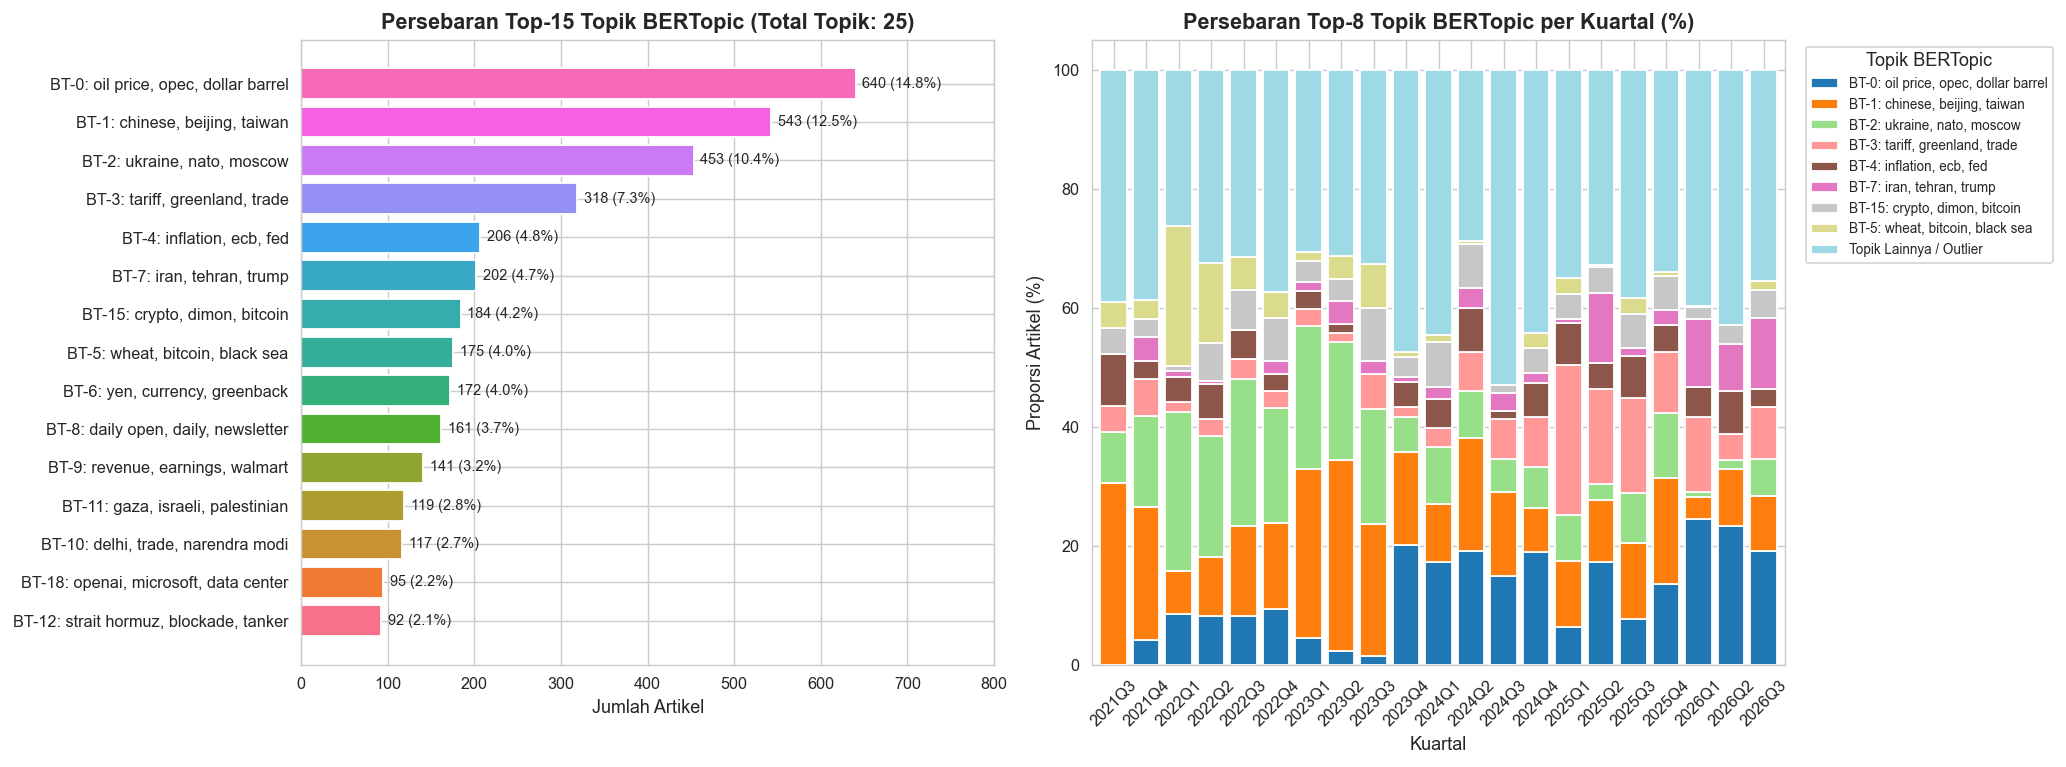

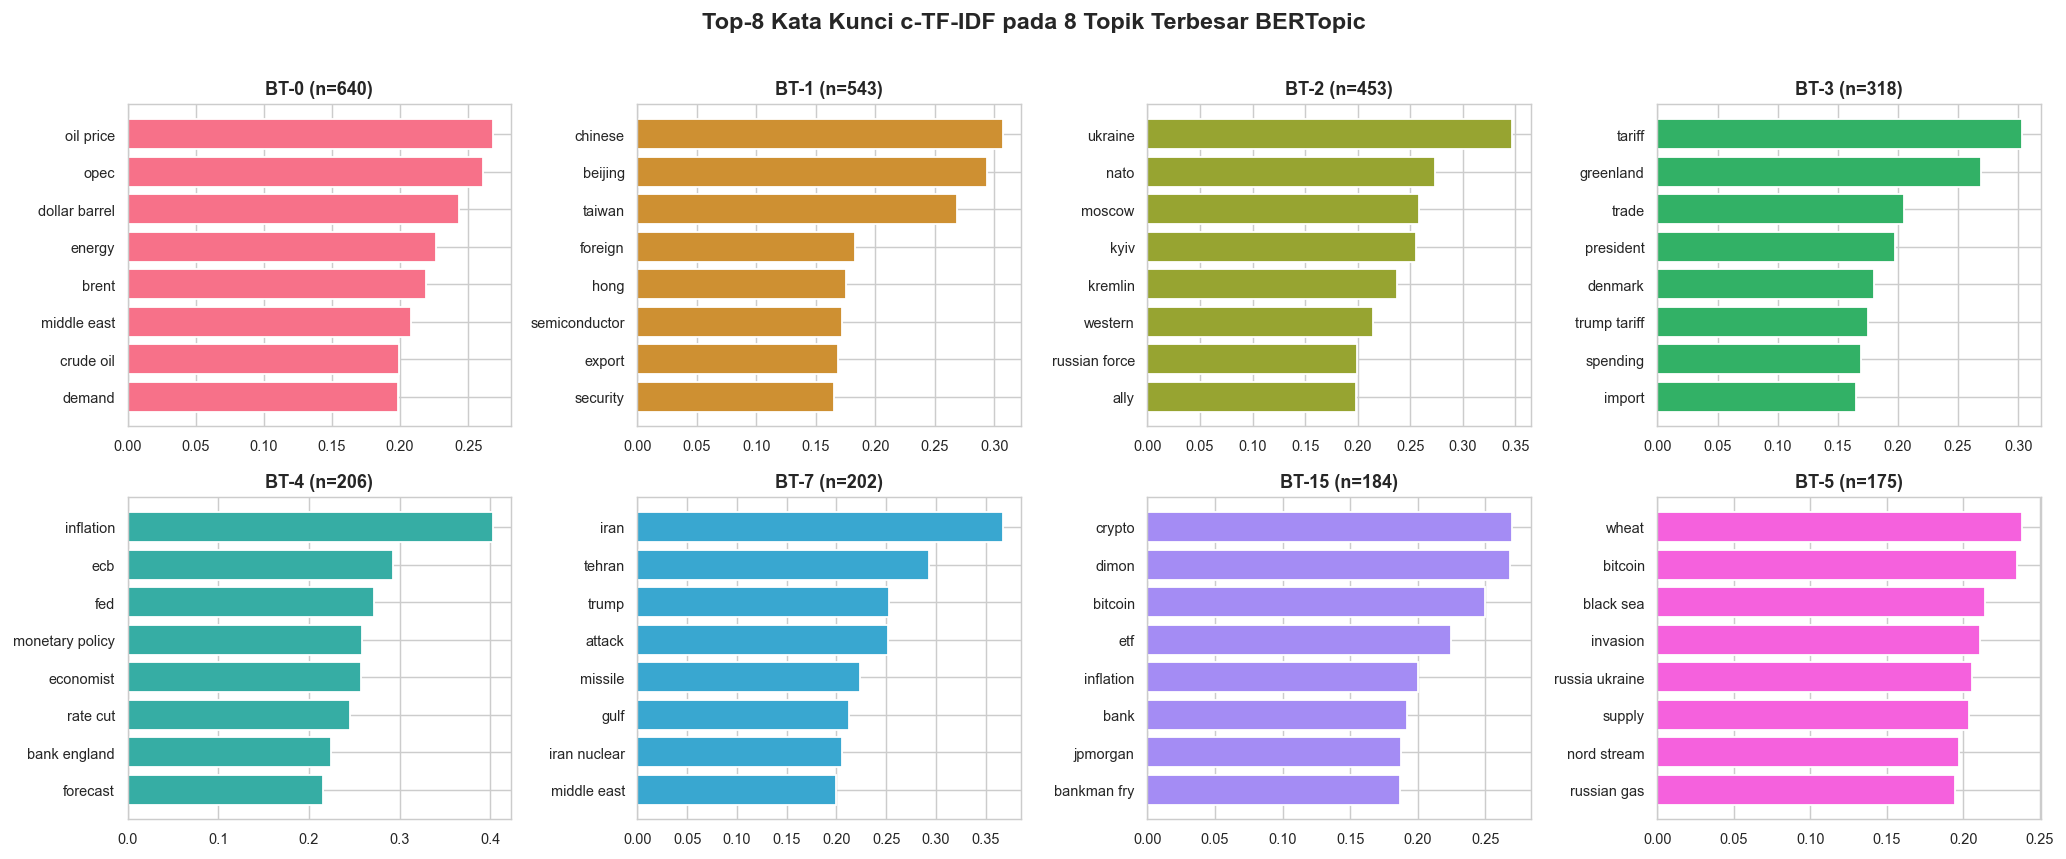

In [9]:
bt_valid_summary = bt_summary_df[bt_summary_df["Topic_ID"] != -1].copy()
top_show = min(15, len(bt_valid_summary))
plot_bt = bt_valid_summary.head(top_show).sort_values("Count", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Bar chart distribusi topik BERTopic (Top 15 + info outlier)
palette_bt = sns.color_palette("husl", n_colors=len(plot_bt))
bars = axes[0].barh(plot_bt["Label"], plot_bt["Count"], color=palette_bt)
for bar, (_, row) in zip(bars, plot_bt.iterrows()):
    axes[0].text(
        bar.get_width() + 8,
        bar.get_y() + bar.get_height() / 2,
        f"{row['Count']} ({row['Share (%)']:.1f}%)",
        va="center",
        fontsize=8,
    )
axes[0].set_xlim(0, plot_bt["Count"].max() * 1.25)
axes[0].set_title(f"Persebaran Top-{top_show} Topik BERTopic (Total Topik: {len(bt_valid_summary)})")
axes[0].set_xlabel("Jumlah Artikel")

# Panel 2: Dinamika 8 topik teratas BERTopic per kuartal
top8_bt_labels = bt_valid_summary.head(8)["Label"].tolist()
df_bt_q = df.copy()
df_bt_q["bt_group"] = np.where(df_bt_q["bt_label"].isin(top8_bt_labels), df_bt_q["bt_label"], "Topik Lainnya / Outlier")
bt_quarter = pd.crosstab(df_bt_q["year_quarter"], df_bt_q["bt_group"], normalize="index") * 100
col_order = [c for c in top8_bt_labels if c in bt_quarter.columns] + (["Topik Lainnya / Outlier"] if "Topik Lainnya / Outlier" in bt_quarter.columns else [])
bt_quarter = bt_quarter[col_order]

bt_quarter.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab20", width=0.82)
axes[1].set_title("Persebaran Top-8 Topik BERTopic per Kuartal (%)")
axes[1].set_ylabel("Proporsi Artikel (%)")
axes[1].set_xlabel("Kuartal")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7.5, title="Topik BERTopic")

plt.tight_layout()
plt.show()

# Multi-panel kata kunci c-TF-IDF untuk 8 topik teratas BERTopic
top8_ids = bt_valid_summary.head(8)["Topic_ID"].tolist()
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
axes = axes.flatten()
for idx, tid in enumerate(top8_ids):
    ax = axes[idx]
    terms = topic_model.get_topic(tid)[:8][::-1]
    words = [w for w, _ in terms]
    scores = [s for _, s in terms]
    ax.barh(words, scores, color=sns.color_palette("husl", len(top8_ids))[idx])
    cnt = int((df["bt_topic"] == tid).sum())
    ax.set_title(f"BT-{tid} (n={cnt})", fontsize=10)
    ax.tick_params(labelsize=8)
for j in range(len(top8_ids), 8):
    axes[j].axis("off")

plt.suptitle("Top-8 Kata Kunci c-TF-IDF pada 8 Topik Terbesar BERTopic", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


In [10]:
# Visualisasi interaktif bawaan BERTopic: Barchart & Topics Over Time
topic_model.visualize_barchart(top_n_topics=10, n_words=8, title="BERTopic: Skor c-TF-IDF Kata Kunci per Topik").show()

tot = topic_model.topics_over_time(docs_bow, timestamps, nr_bins=18)
topic_model.visualize_topics_over_time(tot, top_n_topics=8, title="BERTopic: Evolusi Top-8 Topik dari Waktu ke Waktu").show()


## 6. Visualisasi UMAP Hasil Clustering (BERTopic vs LDA)

Untuk memvisualisasikan struktur klaster secara jelas, kita mereduksi *embedding* 384-D (`all-MiniLM-L6-v2`) ke **2 dimensi dengan UMAP (`n_components=2`)**.

Kita tampilkan tiga sudut pandang UMAP:
1. **UMAP 2D Clustering BERTopic**: sebelum reduksi outlier (menunjukkan titik *noise/outlier* HDBSCAN berwarna abu-abu) vs sesudah reduksi outlier dengan label centroid topik.
2. **Perbandingan Langsung di Ruang UMAP yang Sama**: warna klaster **BERTopic** vs warna topik dominan **LDA**, serta proyeksi **UMAP khusus ruang probabilitas topik LDA ($\theta$)**.
3. **Plot UMAP Interaktif (Plotly)**: untuk mengeksplorasi artikel individual (*hover* judul berita, tanggal, topik BERTopic, dan topik LDA).


In [11]:
# Hitung UMAP 2D pada embedding semantik (digunakan bersama untuk perbandingan visual yang adil)
umap_2d_emb = UMAP(
    n_neighbors=15,
    n_components=2,
    min_dist=0.1,
    metric="cosine",
    random_state=SEED,
).fit_transform(embeddings)

df["umap_x"] = umap_2d_emb[:, 0]
df["umap_y"] = umap_2d_emb[:, 1]

# Hitung juga UMAP 2D langsung dari matriks probabilitas topik LDA (N x K)
umap_2d_lda = UMAP(
    n_neighbors=15,
    n_components=2,
    min_dist=0.15,
    metric="cosine",
    random_state=SEED,
).fit_transform(lda_topic_dist + 1e-6)

df["umap_lda_x"] = umap_2d_lda[:, 0]
df["umap_lda_y"] = umap_2d_lda[:, 1]

print("Proyeksi UMAP 2D selesai:", umap_2d_emb.shape, "| UMAP LDA:", umap_2d_lda.shape)


Proyeksi UMAP 2D selesai: (4335, 2) | UMAP LDA: (4335, 2)


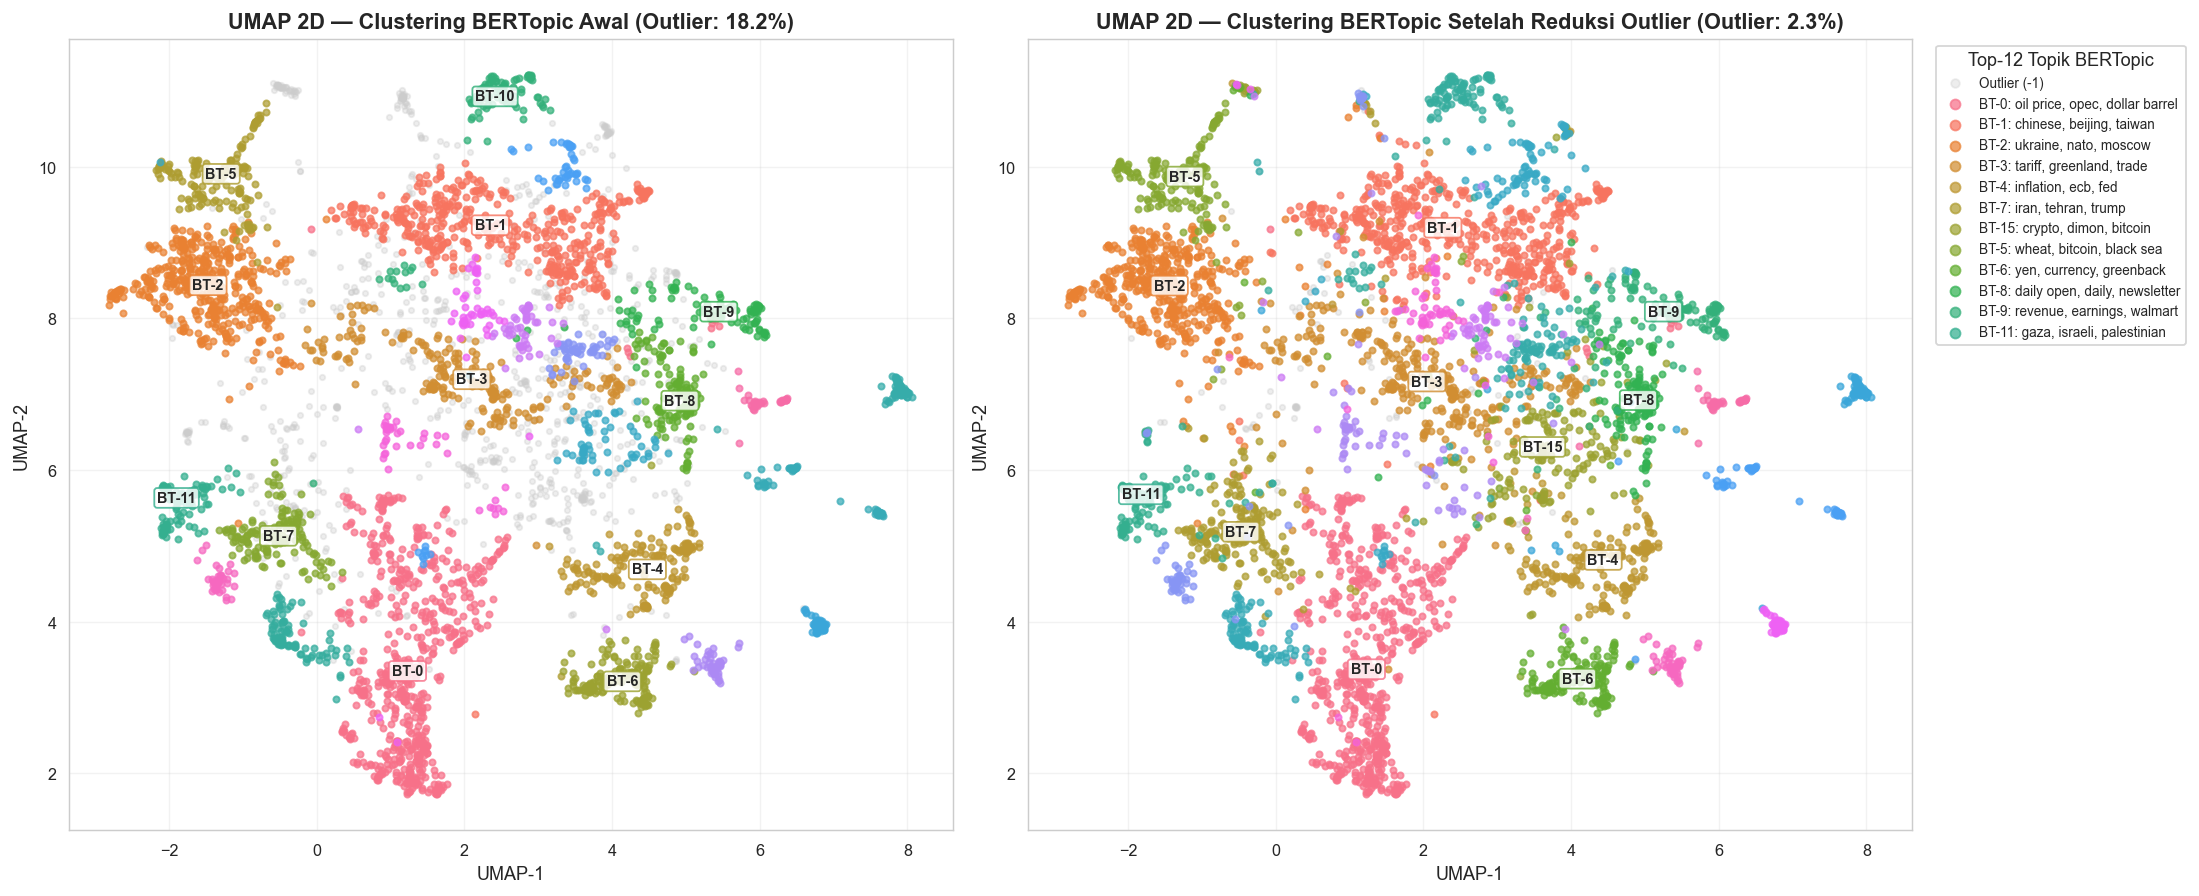

In [12]:
def plot_umap_clusters(ax, x, y, labels, title, highlight_outliers=True, max_legend=12):
    unique_lbls = [l for l in pd.Series(labels).value_counts().index.tolist()]
    valid_lbls = [l for l in unique_lbls if "Outlier" not in str(l) and str(l) != "-1"]
    outlier_lbls = [l for l in unique_lbls if l not in valid_lbls]

    palette = sns.color_palette("husl", n_colors=max(len(valid_lbls), 1))
    color_map = {lbl: palette[i] for i, lbl in enumerate(valid_lbls)}

    if highlight_outliers and outlier_lbls:
        mask_out = np.isin(labels, outlier_lbls)
        ax.scatter(
            x[mask_out], y[mask_out],
            c="#cccccc", s=9, alpha=0.35, label="Outlier (-1)", zorder=1
        )

    for idx, lbl in enumerate(valid_lbls):
        mask = np.array(labels) == lbl
        show_lbl = lbl if idx < max_legend else None
        ax.scatter(
            x[mask], y[mask],
            color=color_map[lbl], s=12, alpha=0.72, label=show_lbl, zorder=2
        )
        # Anotasi centroid untuk 12 klaster terbesar
        if idx < 12:
            cx, cy = np.median(x[mask]), np.median(y[mask])
            short_tag = str(lbl).split(":")[0]
            ax.text(
                cx, cy, short_tag,
                fontsize=8, fontweight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=color_map[lbl], alpha=0.82),
                zorder=4,
            )

    ax.set_title(title)
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")
    ax.grid(True, alpha=0.25)

# 1) UMAP Clustering BERTopic: Sebelum vs Sesudah Reduksi Outlier
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
plot_umap_clusters(
    axes[0], df["umap_x"].values, df["umap_y"].values, df["bt_label_raw"].values,
    f"UMAP 2D — Clustering BERTopic Awal (Outlier: {n_out_raw/len(df)*100:.1f}%)",
    highlight_outliers=True,
)
plot_umap_clusters(
    axes[1], df["umap_x"].values, df["umap_y"].values, df["bt_label"].values,
    f"UMAP 2D — Clustering BERTopic Setelah Reduksi Outlier (Outlier: {n_out_after/len(df)*100:.1f}%)",
    highlight_outliers=True,
)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7.5, markerscale=1.6, title="Top-12 Topik BERTopic")
plt.tight_layout()
plt.show()


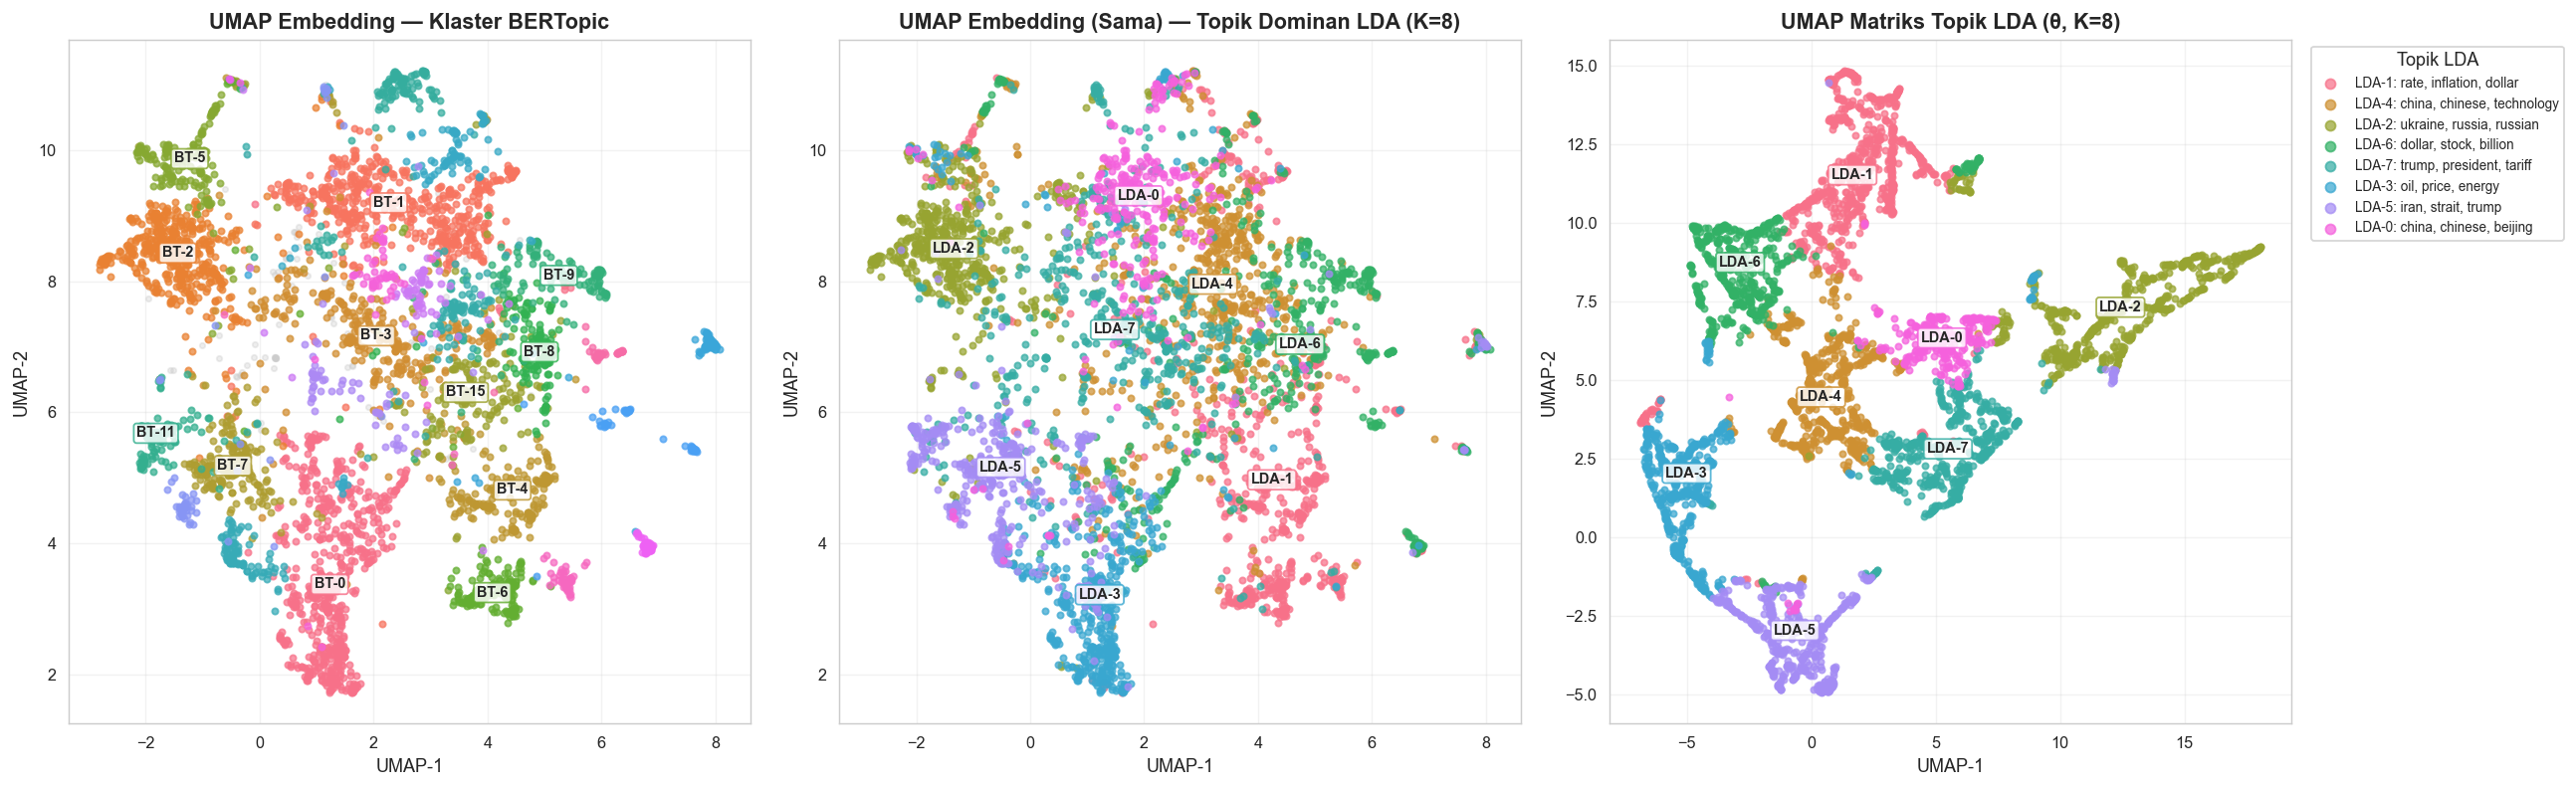

In [13]:
# 2) Perbandingan Visual UMAP: BERTopic vs LDA (di ruang semantik yang sama) + UMAP ruang probabilitas LDA
fig, axes = plt.subplots(1, 3, figsize=(20, 6.2))

plot_umap_clusters(
    axes[0], df["umap_x"].values, df["umap_y"].values, df["bt_label"].values,
    "UMAP Embedding — Klaster BERTopic",
    highlight_outliers=True,
)
plot_umap_clusters(
    axes[1], df["umap_x"].values, df["umap_y"].values, df["lda_label"].values,
    f"UMAP Embedding (Sama) — Topik Dominan LDA (K={best_k})",
    highlight_outliers=False,
)
plot_umap_clusters(
    axes[2], df["umap_lda_x"].values, df["umap_lda_y"].values, df["lda_label"].values,
    f"UMAP Matriks Topik LDA (θ, K={best_k})",
    highlight_outliers=False,
)
axes[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7.5, markerscale=1.6, title="Topik LDA")
plt.tight_layout()
plt.show()


In [14]:
# 3) Plot UMAP Interaktif (Plotly) — Hover untuk melihat judul berita, tanggal, & topik kedua model
df_plot = df.copy()
df_plot["short_title"] = df_plot["title"].str.slice(0, 85)
df_plot["date_str"] = df_plot["date"].dt.strftime("%Y-%m-%d")

fig_interactive = px.scatter(
    df_plot,
    x="umap_x",
    y="umap_y",
    color="bt_label",
    hover_data={
        "short_title": True,
        "date_str": True,
        "bt_label": True,
        "lda_label": True,
        "umap_x": False,
        "umap_y": False,
    },
    title="UMAP 2D Interaktif Clustering BERTopic (Arahkan kursor untuk detail artikel & topik LDA)",
    width=1050,
    height=650,
    opacity=0.72,
)
fig_interactive.update_traces(marker=dict(size=5))
fig_interactive.update_layout(legend_title_text="Topik BERTopic")
fig_interactive.show()


## 7. Perbandingan Kuantitatif & Keselarasan Topik (LDA vs BERTopic)

Kita bandingkan kedua model menggunakan metrik yang adil pada korpus yang sama:
- **Coherence ($c_v$)**: koherensi semantik kata kunci topik menggunakan `shared_dictionary` & `tokens_clean`.
- **Topic Diversity**: proporsi kata unik dari seluruh top-10 kata kunci topik ($0$ = banyak pengulangan, $1$ = sangat beragam).
- **Silhouette Score & Davies-Bouldin Index (pada UMAP 2D)**: mengukur seberapa rapat dan terpisah klaster topik secara geometris di ruang semantik.
- **Normalized Entropy ($H / \log K$)**: mengukur keseimbangan persebaran jumlah artikel antar topik ($1$ = seimbang sempurna).
- **ARI & NMI + Cross-Tabulation Heatmap**: melihat sejauh mana topik LDA dan klaster BERTopic saling berkorespondensi.


In [15]:
def normalized_entropy(labels) -> float:
    counts = pd.Series(labels).value_counts().values
    probs = counts / counts.sum()
    if len(probs) <= 1:
        return 0.0
    h = -(probs * np.log(probs)).sum()
    return float(h / np.log(len(probs)))

def topic_diversity(topic_words_list) -> float:
    flat = [w for ws in topic_words_list for w in ws]
    return float(len(set(flat)) / len(flat)) if flat else 0.0

# 1. LDA metrics
lda_words_all = [[w for w, _ in lda_model.show_topic(tid, topn=10)] for tid in range(best_k)]
lda_coh = CoherenceModel(
    topics=lda_words_all, texts=tokens_clean, dictionary=shared_dictionary, coherence="c_v", processes=1
).get_coherence()
lda_div = topic_diversity(lda_words_all)
lda_sil = silhouette_score(umap_2d_emb, df["lda_topic"].values)
lda_db = davies_bouldin_score(umap_2d_emb, df["lda_topic"].values)
lda_ent = normalized_entropy(df["lda_topic"].values)

# 2. BERTopic metrics (evaluasi pada topik non-outlier; gunakan kata unigram/valid yang ada di dictionary jika perlu)
bt_valid_ids = [int(t) for t in bt_valid_summary["Topic_ID"].tolist()]
bt_words_all = []
bt_words_for_cv = []
for tid in bt_valid_ids:
    ws = [w for w, _ in topic_model.get_topic(tid)]
    bt_words_all.append(ws)
    # Untuk c_v pada kamus unigram bersama, pecah bigram menjadi unigram valid di kamus
    unigrams = []
    for w in ws:
        for part in w.split():
            if part in shared_dictionary.token2id and part not in unigrams:
                unigrams.append(part)
    if len(unigrams) >= 2:
        bt_words_for_cv.append(unigrams[:10])

bt_coh = CoherenceModel(
    topics=bt_words_for_cv, texts=tokens_clean, dictionary=shared_dictionary, coherence="c_v", processes=1
).get_coherence()
bt_div = topic_diversity(bt_words_all)

mask_bt_valid = df["bt_topic"].values != -1
bt_sil = silhouette_score(umap_2d_emb[mask_bt_valid], df.loc[mask_bt_valid, "bt_topic"].values)
bt_db = davies_bouldin_score(umap_2d_emb[mask_bt_valid], df.loc[mask_bt_valid, "bt_topic"].values)
bt_ent = normalized_entropy(df.loc[mask_bt_valid, "bt_topic"].values)

comparison_df = pd.DataFrame([
    {
        "Model": f"LDA (K={best_k})",
        "Jumlah Topik": best_k,
        "Coherence (c_v) ↑": round(lda_coh, 4),
        "Topic Diversity ↑": round(lda_div, 4),
        "Silhouette (UMAP 2D) ↑": round(lda_sil, 4),
        "Davies-Bouldin (UMAP 2D) ↓": round(lda_db, 4),
        "Normalized Entropy ↑": round(lda_ent, 4),
        "Outlier Akhir (%) ↓": 0.0,
    },
    {
        "Model": f"BERTopic (K={len(bt_valid_ids)})",
        "Jumlah Topik": len(bt_valid_ids),
        "Coherence (c_v) ↑": round(bt_coh, 4),
        "Topic Diversity ↑": round(bt_div, 4),
        "Silhouette (UMAP 2D) ↑": round(bt_sil, 4),
        "Davies-Bouldin (UMAP 2D) ↓": round(bt_db, 4),
        "Normalized Entropy ↑": round(bt_ent, 4),
        "Outlier Akhir (%) ↓": round((~mask_bt_valid).mean() * 100, 2),
    },
]).set_index("Model")

ari = adjusted_rand_score(df.loc[mask_bt_valid, "lda_topic"], df.loc[mask_bt_valid, "bt_topic"])
nmi = normalized_mutual_info_score(df.loc[mask_bt_valid, "lda_topic"], df.loc[mask_bt_valid, "bt_topic"])
print(f"Keselarasan Klaster LDA vs BERTopic -> ARI: {ari:.4f} | NMI: {nmi:.4f}")
comparison_df


Keselarasan Klaster LDA vs BERTopic -> ARI: 0.2580 | NMI: 0.3861


,Jumlah Topik,Coherence (c_v) ↑,Topic Diversity ↑,Silhouette (UMAP 2D) ↑,Davies-Bouldin (UMAP 2D) ↓,Normalized Entropy ↑,Outlier Akhir (%) ↓
Model,,,,,,,
LDA (K=8),8,0.6657,0.850,0.0627,2.4277,0.9847,0.00
BERTopic (K=25),25,0.6710,0.908,0.1706,2.0127,0.8985,2.26


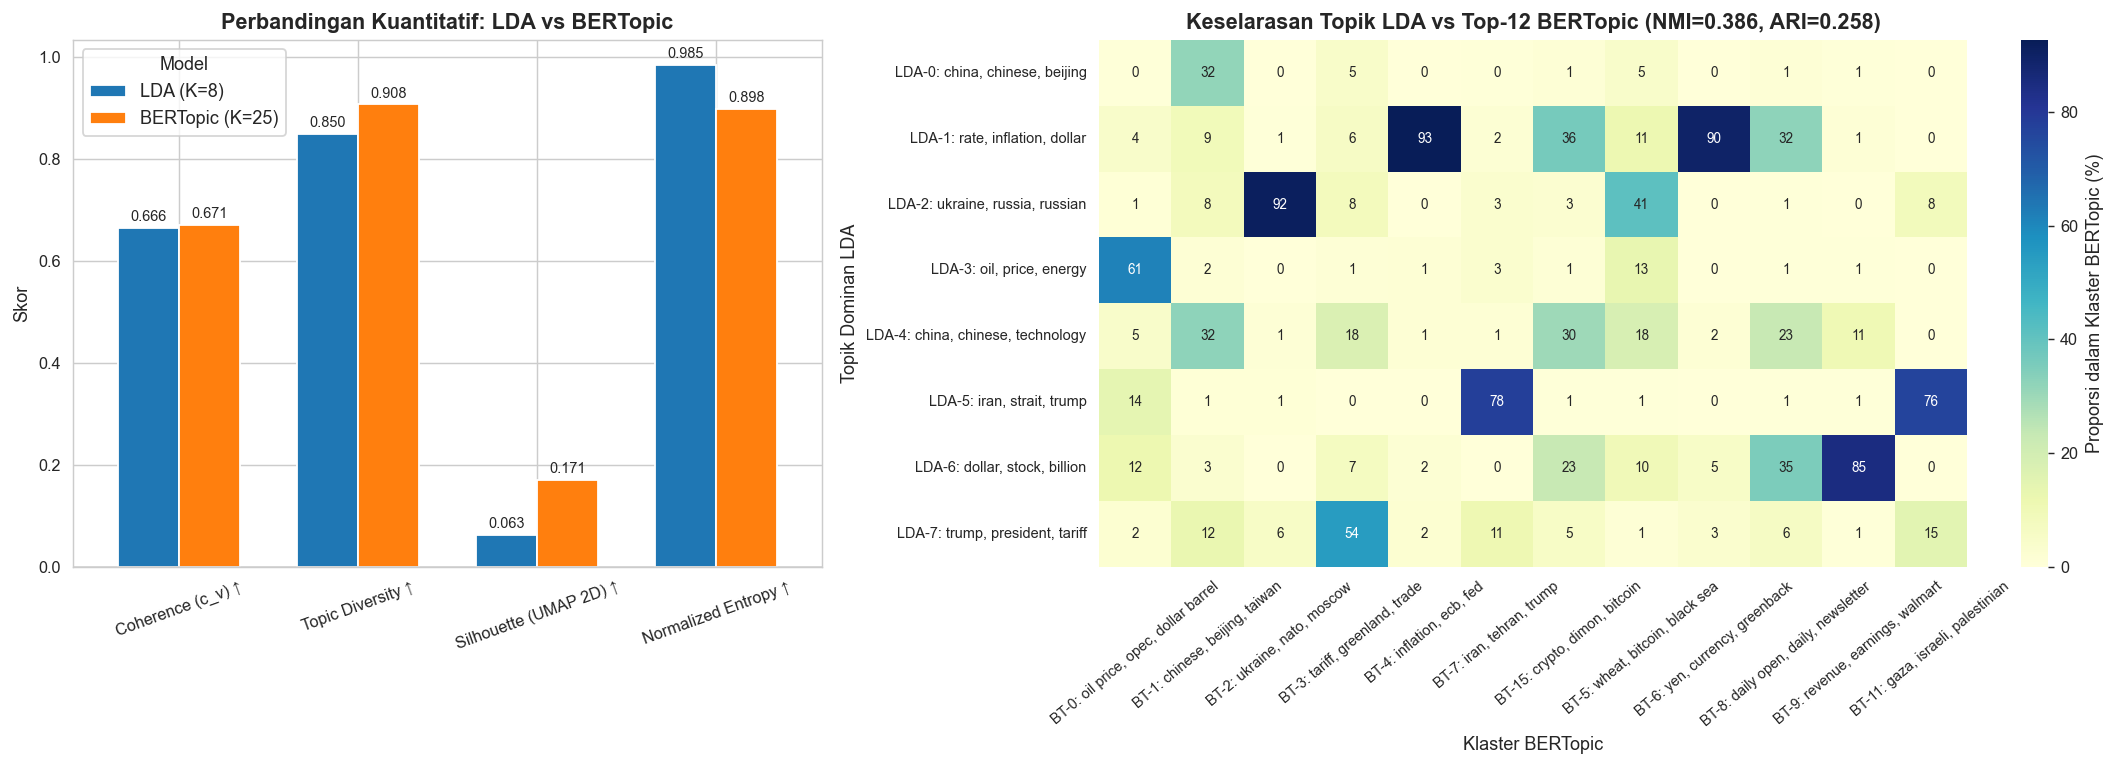

In [16]:
# Visualisasi perbandingan metrik & peta keselarasan (Cross-Tabulation Heatmap)
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.45]})

# Panel 1: Perbandingan Metrik Utama
metrics_plot = comparison_df[["Coherence (c_v) ↑", "Topic Diversity ↑", "Silhouette (UMAP 2D) ↑", "Normalized Entropy ↑"]].T
metrics_plot.plot(kind="bar", ax=axes[0], color=["#1f77b4", "#ff7f0e"], width=0.68)
axes[0].set_title("Perbandingan Kuantitatif: LDA vs BERTopic")
axes[0].set_ylabel("Skor")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].tick_params(axis="x", rotation=20)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=8, padding=2)

# Panel 2: Heatmap Cross-Tabulation Topik LDA vs Top-12 Topik BERTopic
top12_bt = bt_valid_summary.head(12)["Label"].tolist()
df_ct = df[df["bt_label"].isin(top12_bt)]
ct = pd.crosstab(df_ct["lda_label"], df_ct["bt_label"], normalize="columns") * 100
ct = ct.reindex(columns=top12_bt)

sns.heatmap(
    ct, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[1],
    cbar_kws={"label": "Proporsi dalam Klaster BERTopic (%)"},
    annot_kws={"size": 7.5},
)
axes[1].set_title(f"Keselarasan Topik LDA vs Top-12 BERTopic (NMI={nmi:.3f}, ARI={ari:.3f})")
axes[1].set_xlabel("Klaster BERTopic")
axes[1].set_ylabel("Topik Dominan LDA")
axes[1].tick_params(axis="x", rotation=40, labelsize=8)
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()


### 7.1 Inspeksi Kualitatif: Contoh Judul Artikel Representatif

Melihat langsung judul berita yang mewakili setiap topik utama pada **LDA** dan **BERTopic** untuk menilai ketajaman tema masing-masing model.


In [17]:
print("=" * 80)
print("CONTOH ARTIKEL REPRESENTATIF — LDA (berdasarkan probabilitas topik tertinggi)")
print("=" * 80)
for _, row in lda_summary_df.head(5).iterrows():
    tid = int(row["Topic_ID"])
    print(f"\n[{row['Label']}] | n={row['Count']} ({row['Share (%)']}%)")
    sub = df[df["lda_topic"] == tid].sort_values("lda_prob", ascending=False).head(3)
    for _, art in sub.iterrows():
        print(f"  - ({art['date'].strftime('%Y-%m-%d')}, p={art['lda_prob']:.2f}) {art['title']}")

print("\n" + "=" * 80)
print("CONTOH ARTIKEL REPRESENTATIF — BERTopic (Top 5 Klaster Terbesar)")
print("=" * 80)
for _, row in bt_valid_summary.head(5).iterrows():
    tid = int(row["Topic_ID"])
    print(f"\n[{row['Label']}] | n={row['Count']} ({row['Share (%)']}%)")
    sub = df[df["bt_topic"] == tid].head(3)
    for _, art in sub.iterrows():
        print(f"  - ({art['date'].strftime('%Y-%m-%d')}) {art['title']}")


CONTOH ARTIKEL REPRESENTATIF — LDA (berdasarkan probabilitas topik tertinggi)

[LDA-1: rate, inflation, dollar] | n=778 (17.95%)
  - (2026-04-29, p=1.00) Will rates go higher in Europe this week? Central banks confront stagflation threat
  - (2023-11-01, p=1.00) Bank of England set to hold rates again, but markets see no cuts on the ...
  - (2026-08-18, p=1.00) The 30-year Treasury yield just hit a 19-year high. Three things could drive it even ...

[LDA-4: china, chinese, technology] | n=627 (14.46%)
  - (2024-08-23, p=1.00) How Google makes custom chips used to train Apple AI models and its own chatbot, ...
  - (2026-06-12, p=1.00) A Chinese start-up’s unfolding dilemma exposes cracks in Beijing’s tech funding machine
  - (2026-07-11, p=1.00) While Musk’s Neuralink drills into skulls, China’s BrainCo bets the future of brain tech is ...

[LDA-2: ukraine, russia, russian] | n=620 (14.3%)
  - (2022-03-04, p=1.00) Russia’s chaotic and confusing invasion of Ukraine is baffling military a

## 8. Ringkasan & Kesimpulan Perbandingan

- **Granularitas & Persebaran Topik**:
  - **LDA** menghasilkan jumlah topik yang lebih ringkas dan seimbang secara global (*macro-themes*), di mana setiap artikel pasti masuk ke salah satu topik (0% *outlier*). Namun di ruang semantik UMAP, batas antar topik LDA terlihat lebih tumpang tindih karena LDA hanya memodelkan ko-okurensi kata (*bag-of-words*).
  - **BERTopic** memanfaatkan *semantic embeddings* + **UMAP + HDBSCAN**, sehingga mampu memecah berita geopolitik menjadi klaster-klaster tematik yang jauh lebih spesifik dan terpisah tajam pada visualisasi **UMAP 2D** (ditunjukkan oleh *Silhouette Score* yang lebih tinggi).
- **Interpretabilitas & Kegunaan**:
  - Gunakan **BERTopic** jika tujuannya melihat **persebaran topik spesifik, klaster peristiwa geopolitik yang tajam, dan eksplorasi semantik UMAP**.
  - Gunakan **LDA** jika membutuhkan fitur probabilitas topik berdimensi rendah yang stabil dan mencakup 100% dokumen tanpa *outlier* (misalnya sebagai fitur input model prediksi kurs).
